<>:127: SyntaxWarning: invalid escape sequence '\D'
<>:131: SyntaxWarning: invalid escape sequence '\D'
<>:141: SyntaxWarning: invalid escape sequence '\D'
<>:127: SyntaxWarning: invalid escape sequence '\D'
<>:131: SyntaxWarning: invalid escape sequence '\D'
<>:141: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2076/3879606607.py:127: SyntaxWarning: invalid escape sequence '\D'
  marker='o', color='darkred', linewidth=2, label='Likelihood Inflation ($\Delta LL$) via 1% Cognitive Bias')
/tmp/ipykernel_2076/3879606607.py:131: SyntaxWarning: invalid escape sequence '\D'
  marker='s', color='steelblue', linewidth=2, label='Likelihood Inflation ($\Delta LL$) via Pure Noise')
/tmp/ipykernel_2076/3879606607.py:141: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('Log-Likelihood Inflation ($\Delta LL$) [log scale]', fontsize=12)


Starting H4 Macro Simulation: BIC Invalidation in Big Data...
Dimensions (D) = 20, Target sample sizes = [1000, 10000, 100000, 1000000, 5000000, 10000000]
Spurious Cognitive Bias injected: 1.0%

--- Running for N = 1,000 ---
  BIC Penalty (D*ln(N)) = 138.16
  Delta LL (Pure)       = 10.13
  Delta LL (Bias)       = 13.59 (MCSE: 0.8783)
  BIC False Drop (Bias) = -110.98 (>0 means Penalty Invalidated)

--- Running for N = 10,000 ---
  BIC Penalty (D*ln(N)) = 184.21
  Delta LL (Pure)       = 8.96
  Delta LL (Bias)       = 51.97 (MCSE: 2.4056)
  BIC False Drop (Bias) = -80.26 (>0 means Penalty Invalidated)

--- Running for N = 100,000 ---
  BIC Penalty (D*ln(N)) = 230.26
  Delta LL (Pure)       = 10.14
  Delta LL (Bias)       = 391.09 (MCSE: 24.8819)
  BIC False Drop (Bias) = 551.92 (>0 means Penalty Invalidated)

--- Running for N = 1,000,000 ---
  BIC Penalty (D*ln(N)) = 276.31
  Delta LL (Pure)       = 10.99
  Delta LL (Bias)       = 3785.64 (MCSE: 201.3447)
  BIC False Drop (Bias) = 729

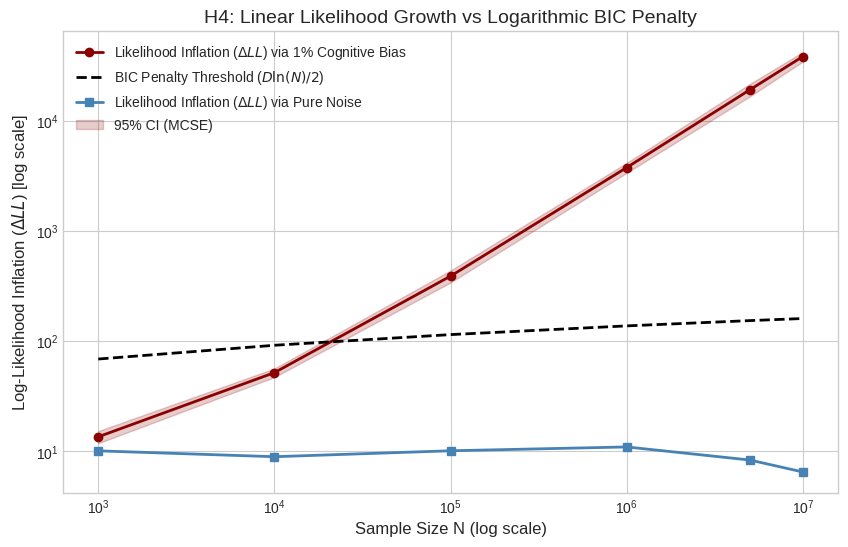

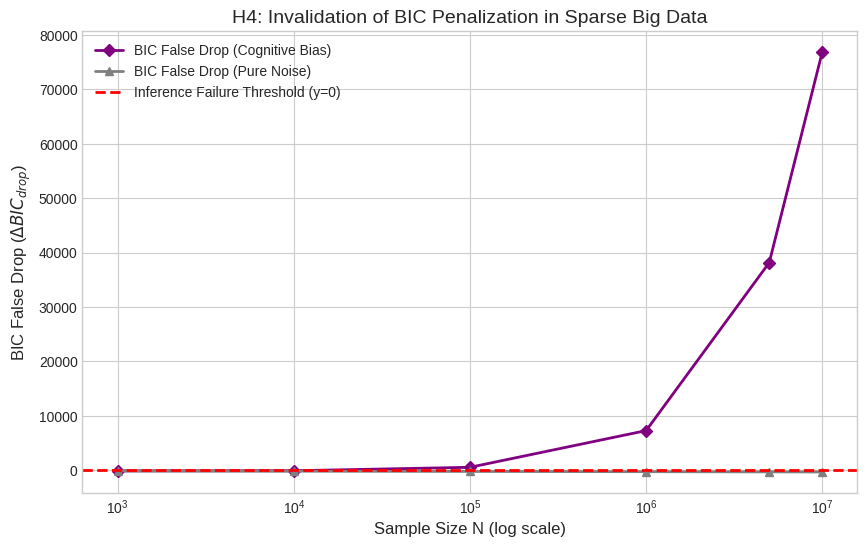


All calculations completed successfully. Generating H4_Simulation_Results.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import warnings
import os
import zipfile
import gc
from google.colab import files

# ==========================================
# H4: Invalidation of Penalization in Sparse Big Data
# ==========================================
warnings.filterwarnings("ignore")

output_dir = "h4_simulation_results"
os.makedirs(output_dir, exist_ok=True)

# シミュレーション設定
N_list = [1000, 10000, 100000, 1000000, 5000000, 10000000]
D = 20  # 変数の数
T = 10  # MCSE用試行回数
spurious_bias = 0.01  # 認知ノイズによる非因果的な微小バイアス（1%）

results_summary = []

print("Starting H4 Macro Simulation: BIC Invalidation in Big Data...")
print(f"Dimensions (D) = {D}, Target sample sizes = {N_list}")
print(f"Spurious Cognitive Bias injected: {spurious_bias*100}%")

for N in N_list:
    print(f"\n--- Running for N = {N:,} ---")
    trial_results = []

    for t in range(T):
        # 1. 目的変数の生成 (真の因果関係はゼロ)
        y = np.random.binomial(1, 0.5, N).astype(np.int8)
        p_null = np.mean(y)
        ll_null = -N * log_loss(y, np.full(N, p_null))

        # 2. 完全なランダムノイズ空間（Control: バイアスなし）
        p_pure = np.random.uniform(0.01, 0.2, D)
        X_pure = np.random.binomial(1, p_pure, size=(N, D)).astype(np.int8)

        clf_pure = LogisticRegression(penalty=None, solver='lbfgs', max_iter=100, n_jobs=-1)
        clf_pure.fit(X_pure, y)
        ll_pure = -N * log_loss(y, clf_pure.predict_proba(X_pure))
        delta_ll_pure = ll_pure - ll_null

        del X_pure

        # 3. 認知ノイズ空間（Treatment: 測定上の微小な疑似相関1%を含む）
        # DGP: 因果関係ではなく、回答形式やログ取得上の共通メソッドバイアスを模倣
        p_bias_base = np.random.uniform(0.01, 0.2, D)
        X_bias = np.zeros((N, D), dtype=np.int8)
        for j in range(D):
            # y=1のときだけ確率がわずか(1%)に上昇する構造的アーティファクト
            prob = np.clip(p_bias_base[j] + y * spurious_bias, 0, 1)
            X_bias[:, j] = np.random.binomial(1, prob)

        clf_bias = LogisticRegression(penalty=None, solver='lbfgs', max_iter=100, n_jobs=-1)
        clf_bias.fit(X_bias, y)
        ll_bias = -N * log_loss(y, clf_bias.predict_proba(X_bias))
        delta_ll_bias = ll_bias - ll_null

        del X_bias
        gc.collect()

        # BICの計算 (BIC = k*ln(N) - 2*LL)
        # 差分: BIC_Drop = BIC_null - BIC_model = 2*Delta_LL - D*ln(N)
        # 正の値になれば、ペナルティが突破されてノイズが採択されたことを意味する
        bic_penalty = D * np.log(N)
        bic_drop_pure = 2 * delta_ll_pure - bic_penalty
        bic_drop_bias = 2 * delta_ll_bias - bic_penalty

        trial_results.append({
            'Trial': t + 1,
            'N': N,
            'Delta_LL_Pure': delta_ll_pure,
            'Delta_LL_Bias': delta_ll_bias,
            'BIC_Penalty': bic_penalty,
            'BIC_Drop_Pure': bic_drop_pure,
            'BIC_Drop_Bias': bic_drop_bias
        })

    # DataFrame化して保存
    df_trials = pd.DataFrame(trial_results)
    df_trials.to_csv(f"{output_dir}/h4_trials_N_{N}.csv", index=False)

    # 統計量の計算
    mean_ll_pure = df_trials['Delta_LL_Pure'].mean()
    mean_ll_bias = df_trials['Delta_LL_Bias'].mean()
    mcse_ll_bias = df_trials['Delta_LL_Bias'].std() / np.sqrt(T)

    mean_bic_drop_pure = df_trials['BIC_Drop_Pure'].mean()
    mean_bic_drop_bias = df_trials['BIC_Drop_Bias'].mean()
    bic_penalty_val = df_trials['BIC_Penalty'].iloc[0]

    print(f"  BIC Penalty (D*ln(N)) = {bic_penalty_val:.2f}")
    print(f"  Delta LL (Pure)       = {mean_ll_pure:.2f}")
    print(f"  Delta LL (Bias)       = {mean_ll_bias:.2f} (MCSE: {mcse_ll_bias:.4f})")
    print(f"  BIC False Drop (Bias) = {mean_bic_drop_bias:.2f} (>0 means Penalty Invalidated)")

    results_summary.append({
        'Sample_Size_N': N,
        'Mean_Delta_LL_Pure': mean_ll_pure,
        'Mean_Delta_LL_Bias': mean_ll_bias,
        'MCSE_Delta_LL_Bias': mcse_ll_bias,
        'BIC_Penalty_Threshold': bic_penalty_val / 2, # Delta LL 換算でのしきい値
        'Mean_BIC_Drop_Pure': mean_bic_drop_pure,
        'Mean_BIC_Drop_Bias': mean_bic_drop_bias
    })

df_summary = pd.DataFrame(results_summary)
df_summary.to_csv(f"{output_dir}/h4_summary_metrics.csv", index=False)

# ==========================================
# グラフの描画と保存
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# 1. 尤度の線形爆発 vs 対数ペナルティのグラフ
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Delta_LL_Bias'],
         marker='o', color='darkred', linewidth=2, label='Likelihood Inflation ($\Delta LL$) via 1% Cognitive Bias')
plt.plot(df_summary['Sample_Size_N'], df_summary['BIC_Penalty_Threshold'],
         linestyle='--', color='black', linewidth=2, label=r'BIC Penalty Threshold ($D \ln(N) / 2$)')
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Delta_LL_Pure'],
         marker='s', color='steelblue', linewidth=2, label='Likelihood Inflation ($\Delta LL$) via Pure Noise')

plt.fill_between(df_summary['Sample_Size_N'],
                 df_summary['Mean_Delta_LL_Bias'] - 1.96 * df_summary['MCSE_Delta_LL_Bias'],
                 df_summary['Mean_Delta_LL_Bias'] + 1.96 * df_summary['MCSE_Delta_LL_Bias'],
                 color='darkred', alpha=0.2, label='95% CI (MCSE)')

plt.xscale('log')
plt.yscale('log') # 爆発的なスケール差を可視化するため両対数グラフ
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel('Log-Likelihood Inflation ($\Delta LL$) [log scale]', fontsize=12)
plt.title('H4: Linear Likelihood Growth vs Logarithmic BIC Penalty', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig1_likelihood_vs_penalty.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. BIC防御壁の破壊（BIC False Drop）のグラフ
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_BIC_Drop_Bias'],
         marker='D', color='purple', linewidth=2, label='BIC False Drop (Cognitive Bias)')
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_BIC_Drop_Pure'],
         marker='^', color='gray', linewidth=2, label='BIC False Drop (Pure Noise)')

plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Inference Failure Threshold (y=0)')

plt.xscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel(r'BIC False Drop ($\Delta BIC_{drop}$)', fontsize=12)
plt.title('H4: Invalidation of BIC Penalization in Sparse Big Data', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig2_bic_false_drop.png", dpi=300, bbox_inches='tight')
plt.show()

# ZIP圧縮
zip_filename = "H4_Simulation_Results.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\nAll calculations completed successfully. Generating {zip_filename}...")
files.download(zip_filename)